# Information Retrieval Project Phase 1
**Sub-topics:** Question Answering · Machine Translation · Text Summarization · Dialogue Systems

Steps: loading the corpus (2) corpus statistics (3) BM25 + dense (4) query handling (5) fusion (6) GUI.



In [1]:
%pip install -q rank_bm25 sentence-transformers symspellpy gradio pandas matplotlib nltk scikit-learn

## 0. Settings

In [2]:
import re, json, html
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
from tqdm.auto import tqdm

DATA = Path("Data")                      # the folder from our GitHub repo
CORPUS_JSON = DATA / "corpus.json"       # metadata of all papers (made by collect_corpus.ipynb)
TEXT_DIR = DATA / "texts"                # full text of each paper, one .txt per paper

## 1. Load the corpus
The corpus was collected by `collect_corpus.ipynb` and saved in `Data/`:
`corpus.json` holds each paper's metadata (title, arXiv ID, link, sub-topic, pages, length tier) and `Data/texts/<arxiv_id>.txt` holds its full text.
This cell joins the two into one list, `corpus`, that the rest of the notebook uses, and checks the Phase 1 corpus requirements.

In [10]:
  !git clone https://github.com/lenaalrashed/InformationRetrieval
  %cd InformationRetrieval

Cloning into 'InformationRetrieval'...
remote: Enumerating objects: 459, done.
remote: Counting objects: 100% (459/459), done.
remote: Compressing objects: 100% (447/447), done.
remote: Total 459 (delta 11), reused 454 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (459/459), 9.94 MiB | 6.74 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/InformationRetrieval


In [11]:
raw = json.load(open("Data/corpus.json", encoding="utf-8"))

corpus = []
for p in raw:
    text_path = TEXT_DIR / Path(p["text_file"]).name
    text = text_path.read_text(encoding="utf-8", errors="ignore") if text_path.exists() else ""
    corpus.append({
        "arxiv_id": p["arxiv_id"],
        "title": p["title"],
        "abstract": p["abstract"],
        "published": p.get("published", ""),
        "primary_category": p.get("primary_category", ""),
        "subtopic": p["subtopic"],
        "pages": p["pages"],
        "length_tier": str(p["length_category"]).lower(),
        "arxiv_url": p["url"],
        "text": " ".join(text.split()),
    })

df = pd.DataFrame(corpus)
N = len(corpus)

missing = (df.text.str.len() == 0).sum()
print(f"{N} papers loaded, {missing} with missing text files")
print("OK  >= 400 papers" if N >= 400 else "NOT OK  fewer than 400 papers")
print("OK  >= 4 sub-topics" if df.subtopic.nunique() >= 4 else "NOT OK  fewer than 4 sub-topics")
print("OK  all 3 length tiers" if {"short", "medium", "long"} <= set(df.length_tier) else "NOT OK  a length tier is missing")
pd.crosstab(df.subtopic, df.length_tier, margins=True)

400 papers loaded, 0 with missing text files
OK  >= 400 papers
OK  >= 4 sub-topics
OK  all 3 length tiers


length_tier,long,medium,short,All
subtopic,,,,
dialogue systems,73,16,11,100
machine translation,79,19,2,100
question answering,78,18,4,100
text summarization,69,22,9,100
All,299,75,26,400


## 2. Corpus statistics report (PDF deliverable)

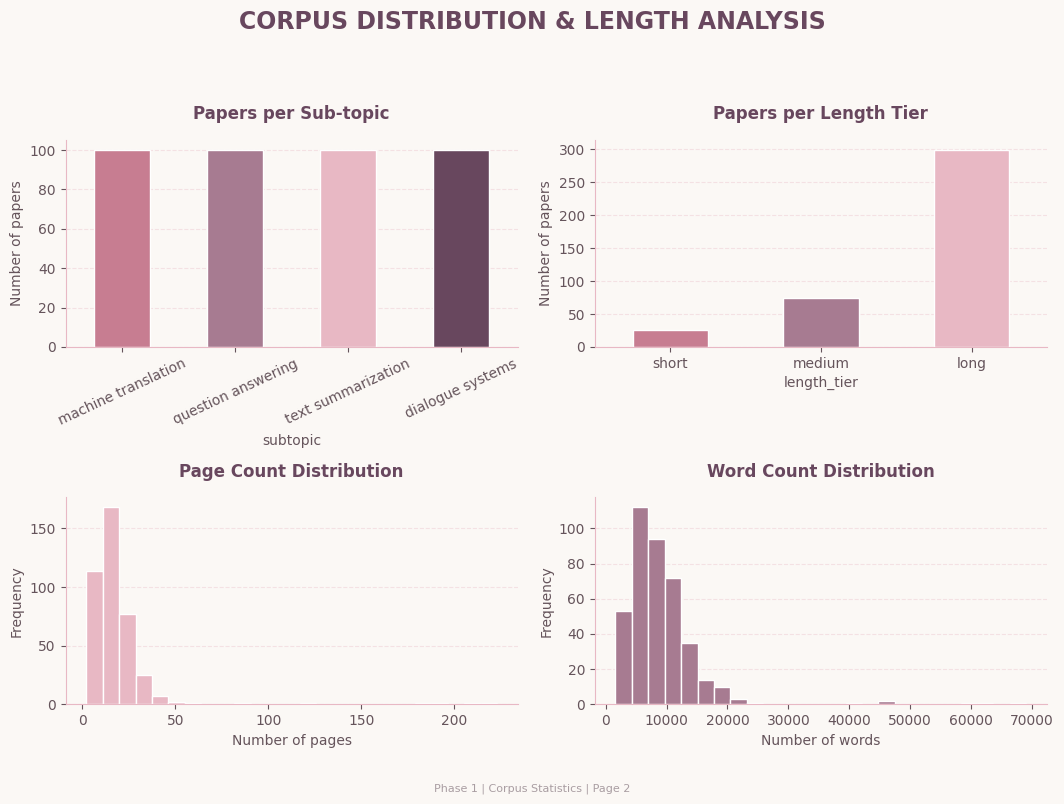

Report successfully saved as: corpus_statistics_report.pdf


In [12]:

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

COLORS = {
    "rose": "#C77D91",
    "pink": "#E8B8C4",
    "mauve": "#A77B91",
    "plum": "#68475E",
    "beige": "#F5EDE8",
    "cream": "#FBF8F5",
    "brown": "#65545B",
    "grey": "#A99DA2",
}

CHART_COLORS = [
    COLORS["rose"],
    COLORS["mauve"],
    COLORS["pink"],
    COLORS["plum"],
    "#D9B8A7",
]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": COLORS["plum"],
    "axes.labelcolor": COLORS["brown"],
    "xtick.color": COLORS["brown"],
    "ytick.color": COLORS["brown"],
    "text.color": COLORS["brown"],
    "figure.facecolor": COLORS["cream"],
    "axes.facecolor": COLORS["cream"],
    "axes.edgecolor": COLORS["pink"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": COLORS["pink"],
    "grid.alpha": 0.35,
    "savefig.facecolor": COLORS["cream"],
})


# DATA PREPARATION

# Count words in each paper
df["words"] = df["text"].fillna("").str.split().str.len()

# Papers per sub-topic and length tier
table = pd.crosstab(
    df["subtopic"],
    df["length_tier"],
    margins=True
)

# Summary statistics for each sub-topic
stats = (
    df.groupby("subtopic")
    .agg(
        papers=("arxiv_id", "count"),
        avg_pages=("pages", "mean"),
        avg_words=("words", "mean")
    )
    .round(1)
)

# Calculate percentage of the total corpus
stats["corpus_percentage"] = (
    stats["papers"] / len(df) * 100
).round(1)

# Load collection information
with open(DATA / "collection_log.json", encoding="utf-8") as file:
    log = json.load(file)

# Basic corpus information
total_papers = len(df)
total_subtopics = df["subtopic"].nunique()
first_year = df["published"].min()
last_year = df["published"].max()


def style_chart(ax, title, ylabel=None):
    """Apply consistent styling to charts."""
    ax.set_title(title, pad=15)
    ax.set_ylabel(ylabel if ylabel else "")
    ax.grid(axis="y", linestyle="--")
    ax.set_axisbelow(True)


def add_footer(fig, page_number):
    """Add a footer to each PDF page."""
    fig.text(
        0.5, 0.025,
        f"Phase 1 | Corpus Statistics | Page {page_number}",
        ha="center",
        fontsize=8,
        color=COLORS["grey"]
    )




output_file = "corpus_statistics_report.pdf"

with PdfPages(output_file) as pdf:


    # PAGE 1: CORPUS INFORMATION & STATISTICS TABLES

    fig = plt.figure(figsize=(8.27, 11.69))
    fig.patch.set_facecolor(COLORS["cream"])

    # Report title
    fig.text(
        0.08, 0.95,
        "CORPUS STATISTICS REPORT",
        fontsize=19,
        weight="bold",
        color=COLORS["plum"]
    )

    fig.text(
        0.08, 0.925,
        "Phase 1 | arXiv Computer Science - Computation and Language (cs.CL)",
        fontsize=9,
        color=COLORS["mauve"]
    )

    # Corpus overview
    overview = [
        f"Total papers collected: {total_papers}",
        f"Number of sub-topics: {total_subtopics}",
        f"Publication period: {first_year} - {last_year}",
    ]

    y = 0.87

    for item in overview:
        fig.text(
            0.09, y, f"• {item}",
            fontsize=11,
            color=COLORS["brown"]
        )
        y -= 0.035

    # Collection methodology
    fig.text(
        0.08, 0.745,
        "COLLECTION INFORMATION",
        fontsize=12,
        weight="bold",
        color=COLORS["rose"]
    )

    log_text = json.dumps(log, indent=2, ensure_ascii=False)

    # Keep the collection log readable
    log_lines = log_text.splitlines()[:18]

    y = 0.715

    for line in log_lines:
        fig.text(
            0.09, y, line[:105],
            fontsize=8,
            family="monospace",
            color=COLORS["brown"]
        )
        y -= 0.018

    # Papers per sub-topic and length tier
    fig.text(
        0.08, 0.365,
        "PAPERS BY SUB-TOPIC AND LENGTH",
        fontsize=12,
        weight="bold",
        color=COLORS["rose"]
    )

    fig.text(
        0.09, 0.335,
        table.to_string(),
        fontsize=8,
        family="monospace",
        color=COLORS["brown"],
        va="top"
    )

    # Average statistics
    fig.text(
        0.08, 0.205,
        "SUMMARY STATISTICS BY SUB-TOPIC",
        fontsize=12,
        weight="bold",
        color=COLORS["rose"]
    )

    fig.text(
        0.09, 0.175,
        stats.to_string(),
        fontsize=8,
        family="monospace",
        color=COLORS["brown"],
        va="top"
    )

    fig.text(
        0.08, 0.07,
        "Length categories are based on the number of pages in each arXiv PDF.",
        fontsize=8,
        color=COLORS["grey"]
    )

    add_footer(fig, 1)

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # PAGE 2: VISUAL STATISTICAL ANALYSIS


    fig, axes = plt.subplots(
        2, 2,
        figsize=(11.69, 8.27)
    )

    fig.suptitle(
        "CORPUS DISTRIBUTION & LENGTH ANALYSIS",
        fontsize=17,
        weight="bold",
        color=COLORS["plum"],
        y=0.97
    )

    # Chart 1: Papers per sub-topic
    ax = axes[0, 0]

    counts = df["subtopic"].value_counts()

    counts.plot.bar(
        ax=ax,
        color=CHART_COLORS,
        edgecolor="white",
        rot=25
    )

    style_chart(ax, "Papers per Sub-topic", "Number of papers")

    # Chart 2: Papers per length tier
    ax = axes[0, 1]

    tier_order = ["short", "medium", "long"]

    tier_counts = (
        df["length_tier"]
        .value_counts()
        .reindex(tier_order, fill_value=0)
    )

    tier_counts.plot.bar(
        ax=ax,
        color=CHART_COLORS[:3],
        edgecolor="white",
        rot=0
    )

    style_chart(ax, "Papers per Length Tier", "Number of papers")

    # Chart 3: Page count distribution
    ax = axes[1, 0]

    df["pages"].dropna().plot.hist(
        bins=25,
        ax=ax,
        color=COLORS["pink"],
        edgecolor="white"
    )

    style_chart(ax, "Page Count Distribution", "Frequency")
    ax.set_xlabel("Number of pages")

    # Chart 4: Word count distribution
    ax = axes[1, 1]

    df["words"].plot.hist(
        bins=25,
        ax=ax,
        color=COLORS["mauve"],
        edgecolor="white"
    )

    style_chart(ax, "Word Count Distribution", "Frequency")
    ax.set_xlabel("Number of words")

    fig.tight_layout(rect=[0.04, 0.06, 0.96, 0.92])

    add_footer(fig, 2)

    pdf.savefig(fig, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print(f"Report successfully saved as: {output_file}")


## 3. Indexes
**BM25:** text is lower-cased (→ case-insensitive), stop words removed, Porter-stemmed. Indexed field = title + abstract + full text.
**Dense:** each paper's title + abstract is embedded with `all-MiniLM-L6-v2`; similarity = cosine.

In [13]:
from rank_bm25 import BM25Okapi
from nltk.stem import PorterStemmer
from sentence_transformers import SentenceTransformer, CrossEncoder
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stemmer = PorterStemmer()

def tokenize(text):
    words = re.findall(r"[a-z0-9]+", text.lower())
    return [stemmer.stem(w) for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 1]

bm25 = BM25Okapi([tokenize(d["title"] + " " + d["abstract"] + " " + d["text"]) for d in tqdm(corpus)])

dense_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
doc_emb = dense_model.encode([d["title"] + ". " + d["abstract"] for d in corpus],
                             normalize_embeddings=True, show_progress_bar=True)
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
print("indexes ready")

  0%|          | 0/400 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (14 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

indexes ready


## 4. Query handling
- **Case-insensitive:** query lower-cased.
- **Spelling correction:** SymSpell, dictionary = words of our own corpus, so NLP terms are known.
- **Abbreviation expansion:** e.g. `nmt` → adds "neural machine translation" (the acronym is kept too).
- **Phrase matching:** text in `"quotes"` must appear exactly in the paper.

In [24]:

ABBREVIATIONS = {
    # general NLP / LLMs
    "nlp": "natural language processing",
    "nlu": "natural language understanding",
    "nlg": "natural language generation",
    "llm": "large language model", "llms": "large language models",
    "lm": "language model", "lms": "language models",
    "plm": "pretrained language model", "plms": "pretrained language models",
    "slm": "small language model",
    "mllm": "multimodal large language model",
    "vlm": "vision language model",
    "mlm": "masked language model",
    "bert": "bidirectional encoder representations from transformers",
    "gpt": "generative pretrained transformer",
    "rag": "retrieval augmented generation",
    "cot": "chain of thought",
    "icl": "in context learning",
    "sft": "supervised fine tuning",
    "rlhf": "reinforcement learning from human feedback",
    "rl": "reinforcement learning",
    "dpo": "direct preference optimization",
    "peft": "parameter efficient fine tuning",
    "lora": "low rank adaptation",
    "moe": "mixture of experts",
    "ood": "out of distribution",
    "oov": "out of vocabulary",
    "ie": "information extraction",
    "ir": "information retrieval",
    "kg": "knowledge graph",
    "ner": "named entity recognition",
    "nli": "natural language inference",
    "wsd": "word sense disambiguation",
    "srl": "semantic role labeling",
    "amr": "abstract meaning representation",
    "sts": "semantic textual similarity",
    "asr": "automatic speech recognition",
    "tts": "text to speech",

    # machine translation
    "mt": "machine translation",
    "nmt": "neural machine translation",
    "smt": "statistical machine translation",
    "qe": "quality estimation",
    "lrl": "low resource language",
    "clir": "cross lingual information retrieval",

    # question answering
    "qa": "question answering",
    "odqa": "open domain question answering",
    "kbqa": "knowledge base question answering",
    "cqa": "community question answering",
    "vqa": "visual question answering",
    "mcqa": "multiple choice question answering",
    "mrc": "machine reading comprehension",

    # summarization
    "mds": "multi document summarization",
    "ats": "automatic text summarization",

    # dialogue systems
    "dst": "dialogue state tracking",
    "tod": "task oriented dialogue",
    "crs": "conversational recommender system",
}

In [25]:
from symspellpy import SymSpell, Verbosity

spell = SymSpell(max_dictionary_edit_distance=2)
word_counts = Counter(w for d in corpus for w in re.findall(r"[a-z]+", (d["title"] + " " + d["abstract"] + " " + d["text"]).lower()))
for w, c in word_counts.items():
    if c >= 3 and len(w) >= 3:
        spell.create_dictionary_entry(w, c)

def process_query(query, use_spell=True, use_abbr=True):
    q = query.lower()
    corrections, expansions = {}, {}
    if use_spell:
        def fix(m):
            w = m.group(0)
            if len(w) < 3 or w in ABBREVIATIONS or w in spell.words:
                return w
            s = spell.lookup(w, Verbosity.CLOSEST, max_edit_distance=2)
            if s and s[0].term != w:
                corrections[w] = s[0].term
                return s[0].term
            return w
        q = re.sub(r"[a-z]+", fix, q)
    phrases = re.findall(r'"([^"]+)"', q)
    plain = q.replace('"', " ")
    if use_abbr:
        for w in re.findall(r"[a-z0-9]+", plain):
            if w in ABBREVIATIONS:
                expansions[w] = ABBREVIATIONS[w]
    full = plain + " " + " ".join(expansions.values())
    return {"text": " ".join(full.split()), "tokens": tokenize(full), "phrases": phrases,
            "corrections": corrections, "expansions": expansions}

process_query('NMT for low-resourse langauges "machine translation"') #testing

{'text': 'nmt for low-resource languages machine translation neural machine translation',
 'tokens': ['nmt',
  'low',
  'resourc',
  'languag',
  'machin',
  'translat',
  'neural',
  'machin',
  'translat'],
 'phrases': ['machine translation'],
 'corrections': {'resourse': 'resource', 'langauges': 'languages'},
 'expansions': {'nmt': 'neural machine translation'}}

## 5. Retrieval: BM25, Dense, RRF fusion, RRF + rerank
**RRF:** `score(d) = 1/(60 + rank_BM25(d)) + 1/(60 + rank_dense(d))`. It uses ranks, not raw scores, so the different score scales of BM25 and cosine don't matter.
**Rerank:** the RRF top-30 is re-scored by a cross-encoder, which reads query and paper together (more accurate, but too slow for the whole corpus).

In [17]:
def phrase_ok(doc, phrases):

    text = (
        doc["title"] + " " +
        doc["abstract"] + " " +
        doc["text"]
    ).lower()

    return all(phrase.lower() in text for phrase in phrases)


from collections import Counter


def search(
    query,
    method="RRF fusion",
    use_spell=True,
    use_abbr=True,
    k=10,
    candidate_k=100
):

    # STEP 1: Process query
    q = process_query(query, use_spell, use_abbr)

    # STEP 2: Identify eligible papers
    if q["phrases"]:
        allowed = [
            i for i, doc in enumerate(corpus)
            if phrase_ok(doc, q["phrases"])
        ]
    else:
        allowed = list(range(len(corpus)))

    if not allowed:
        return [], q

    # STEP 3: Calculate retrieval scores
    bm25_scores = bm25.get_scores(q["tokens"])

    query_embedding = dense_model.encode(
        q["text"],
        normalize_embeddings=True,
        convert_to_numpy=True
    )

    dense_scores = doc_emb @ query_embedding

    # STEP 4: Rank eligible documents
    bm25_rank = sorted(
        allowed,
        key=lambda i: bm25_scores[i],
        reverse=True
    )

    dense_rank = sorted(
        allowed,
        key=lambda i: dense_scores[i],
        reverse=True
    )

    # STEP 5: Select retrieval method
    if method == "BM25":

        results = [
            (i, float(bm25_scores[i]))
            for i in bm25_rank[:k]
        ]

    elif method == "Dense":

        results = [
            (i, float(dense_scores[i]))
            for i in dense_rank[:k]
        ]

    elif method in ("RRF fusion", "RRF + rerank"):

        # Combine the two rankings using RRF
        rrf_scores = Counter()

        for ranking in (bm25_rank[:candidate_k],
                        dense_rank[:candidate_k]):

            for rank, doc_id in enumerate(ranking, start=1):

                rrf_scores[doc_id] += 1 / (60 + rank)

        # Keep the strongest candidates
        pool = rrf_scores.most_common(
            candidate_k if method == "RRF + rerank" else k
        )

        if method == "RRF fusion":

            results = [
                (doc_id, float(score))
                for doc_id, score in pool
            ]

        else:

            # CrossEncoder reranking
            candidate_ids = [doc_id for doc_id, score in pool]

            pairs = [
                (
                    q["text"],
                    corpus[i]["title"] + ". " +
                    corpus[i]["abstract"]
                )
                for i in candidate_ids
            ]

            ce_scores = reranker.predict(
                pairs,
                show_progress_bar=False
            )

            results = sorted(
                [
                    (doc_id, float(score))
                    for doc_id, score in zip(candidate_ids, ce_scores)
                ],
                key=lambda x: x[1],
                reverse=True
            )[:k]

    else:
        raise ValueError(
            "Invalid method. Choose BM25, Dense, RRF fusion, or RRF + rerank."
        )

    return results, q


#test search

query = "low resource neural machine translation"

results, processed_query = search(
    query,
    method="RRF + rerank",
    k=10
)

print("Original query:", query)
print("Processed query:", processed_query["text"])
print("\nTop results:\n")

for rank, (doc_id, score) in enumerate(results[:5], start=1):

    print(f"{rank}. {corpus[doc_id]['title']}")
    print(f"   arXiv ID: {corpus[doc_id]['arxiv_id']}")
    print(f"   Score: {score:.4f}\n")


Original query: low resource neural machine translation
Processed query: low resource neural machine translation

Top results:

1. Low-Resource Neural Machine Translation Using Recurrent Neural Networks and Transfer Learning: A Case Study on English-to-Igbo
   arXiv ID: 2504.17252
   Score: 9.0897

2. BhashaSetu: A Data-Centric Approach to Low-Resource Machine Translation
   arXiv ID: 2605.27050
   Score: 7.9322

3. TULUN: Transparent and Adaptable Low-resource Machine Translation
   arXiv ID: 2505.18683
   Score: 7.8803

4. MERIT: Multilingual Expert-Reward Informed Tuning for Chinese-Centric Low-Resource Machine Translation
   arXiv ID: 2604.04839
   Score: 7.7652

5. Neural Machine Translation for Low-Resource Tangkhul--English
   arXiv ID: 2606.25365
   Score: 7.5222



## 6. GUI

In [21]:
custom_css = """

/* Main background */
.gradio-container {
    background: #FFF8F7 !important;
    font-family: 'Inter', sans-serif !important;
}

/* Main content */
.main {
    max-width: 1050px !important;
}

/* Header */
.header-box {
    background: linear-gradient(135deg, #F7DCE4, #FBECE9);
    padding: 35px 30px;
    border-radius: 22px;
    text-align: center;
    margin-bottom: 22px;
    border: 1px solid #EBC8D2;
}

.header-box h1 {
    color: #75475D;
    font-size: 30px;
    margin-bottom: 8px;
}

.header-box p {
    color: #967184;
    font-size: 14px;
}

/* Search area */
.search-box {
    background: white;
    padding: 24px;
    border-radius: 18px;
    border: 1px solid #F0DCE3;
    box-shadow: 0 4px 15px rgba(150, 90, 115, 0.06);
}

/* Search button */
button.primary {
    background: #C77D99 !important;
    border: none !important;
    color: white !important;
    border-radius: 12px !important;
    font-weight: 600 !important;
}

button.primary:hover {
    background: #A95F7D !important;
}

/* Query information */
.query-info {
    background: #FCEEF2;
    border-left: 4px solid #C77D99;
    padding: 17px 20px;
    border-radius: 12px;
    margin: 20px 0;
}

.section-label {
    color: #AE7189;
    font-size: 10px;
    font-weight: 800;
    letter-spacing: 2px;
    margin-bottom: 8px;
}

.query-text {
    color: #68475E;
    font-size: 17px;
    font-weight: 600;
}

.query-tag {
    display: inline-block;
    background: white;
    color: #91677C;
    border: 1px solid #EBD2DC;
    padding: 6px 10px;
    border-radius: 20px;
    font-size: 11px;
    margin: 10px 5px 0 0;
}

/* Results header */
.results-header {
    display: flex;
    justify-content: space-between;
    align-items: center;
    margin: 25px 0 15px;
}

.results-header h3 {
    color: #75475D;
    margin: 0;
}

.result-count {
    background: #F2DCE5;
    color: #89556F;
    border-radius: 20px;
    padding: 7px 14px;
    font-size: 12px;
    font-weight: 700;
}

/* Paper cards */
.paper-card {
    background: white;
    border: 1px solid #F0DDE4;
    border-radius: 16px;
    padding: 20px;
    margin: 13px 0;
    box-shadow: 0 3px 12px rgba(130, 80, 100, 0.05);
    transition: 0.2s ease;
}

.paper-card:hover {
    border-color: #D99CB2;
    box-shadow: 0 6px 18px rgba(150, 90, 115, 0.12);
}

/* Rank and score */
.paper-top {
    display: flex;
    justify-content: space-between;
    margin-bottom: 12px;
}

.rank {
    color: #B46F8A;
    background: #FCEAF0;
    padding: 4px 11px;
    border-radius: 8px;
    font-size: 12px;
    font-weight: 800;
}

.score {
    color: #99768A;
    font-size: 12px;
}

/* Paper title */
.paper-title {
    display: block;
    color: #68475E !important;
    font-size: 17px;
    font-weight: 700;
    line-height: 1.5;
    text-decoration: none !important;
    margin-bottom: 12px;
}

.paper-title:hover {
    color: #C77D99 !important;
}

/* Metadata */
.paper-meta {
    display: flex;
    flex-wrap: wrap;
    gap: 9px;
    margin-bottom: 15px;
    color: #987D8B;
    font-size: 11px;
}

.tier {
    background: #F8EEF2;
    padding: 2px 9px;
    border-radius: 10px;
}

/* Abstract */
.abstract {
    color: #776873;
    font-size: 13px;
    line-height: 1.8;
    padding: 12px;
    background: #FFFAFA;
    border-radius: 10px;
}

/* Highlighted keywords */
.highlight {
    background: #F7D5E1;
    color: #783E5B;
    font-weight: 700;
    padding: 1px 3px;
    border-radius: 4px;
}

/* Read paper link */
.read-link {
    display: inline-block;
    color: #BC7793 !important;
    font-size: 12px;
    font-weight: 700;
    text-decoration: none !important;
    margin-top: 13px;
}

/* Empty state */
.empty-state {
    background: white;
    border: 1px dashed #DDAFC0;
    border-radius: 18px;
    text-align: center;
    padding: 45px 20px;
    margin-top: 20px;
}

.empty-icon {
    font-size: 35px;
}

.empty-state h3 {
    color: #75475D;
}

.empty-state p {
    color: #A08795;
    font-size: 13px;
}

"""


In [23]:

import gradio as gr
import re
import html


def snippet(doc, q, size=250):

    text = doc["abstract"]
    stems = set(q["tokens"])
    words = text.split()

    start = next(
        (
            j for j, word in enumerate(words)
            if any(token in stems for token in tokenize(word))
        ),
        0
    )

    selected = words[max(0, start - 5):]
    result = " ".join(selected)[:size]

    return ("... " if start > 5 else "") + result + "..."


def highlight(text, q):

    stems = set(q["tokens"])

    def replace(match):

        word = match.group(0)
        word_tokens = tokenize(word)

        if word_tokens and word_tokens[0] in stems:
            return (
                '<span class="highlight">'
                + html.escape(word)
                + '</span>'
            )

        return html.escape(word)

    return re.sub(
        r"[A-Za-z0-9]+",
        replace,
        str(text)
    )



def run(query, method, use_spell, use_abbr):

    if not query.strip():
        return """
        <div class="empty-state">
            <div class="empty-icon">🔎</div>
            <h3>Waiting for your research question</h3>
            <p>Enter a topic, concept, or research question to get started.</p>
        </div>
        """

    results, q = search(
        query,
        method,
        use_spell,
        use_abbr
    )

    # Query information
    info = f"""
    <div class="query-info">
        <div class="section-label">YOUR SEARCH</div>
        <div class="query-text">{html.escape(q['text'])}</div>
    """

    if q["corrections"]:
        info += f"""
        <div class="query-tag">
            ✏️ Spelling corrected:
            {html.escape(str(q['corrections']))}
        </div>
        """

    if q["expansions"]:
        info += f"""
        <div class="query-tag">
            ✨ Abbreviations expanded:
            {html.escape(str(q['expansions']))}
        </div>
        """

    if q["phrases"]:
        info += f"""
        <div class="query-tag">
            💬 Exact phrases:
            {html.escape(str(q['phrases']))}
        </div>
        """

    info += "</div>"

    if not results:
        return info + """
        <div class="empty-state">
            <div class="empty-icon">🌷</div>
            <h3>No papers found</h3>
            <p>Try changing your search terms or disabling exact phrase filtering.</p>
        </div>
        """

    # Results header
    cards = f"""
    <div class="results-header">
        <div>
            <div class="section-label">SEARCH RESULTS</div>
            <h3>Research papers found </h3>
        </div>
        <div class="result-count">{len(results)} results</div>
    </div>
    """

    # Individual paper cards
    for rank, (i, score) in enumerate(results, 1):

        d = corpus[i]

        cards += f"""
        <div class="paper-card">

            <div class="paper-top">
                <span class="rank">#{rank}</span>
                <span class="score">Score: {float(score):.4f}</span>
            </div>

            <a class="paper-title"
               href="{html.escape(str(d['arxiv_url']), quote=True)}"
               target="_blank"
               rel="noopener noreferrer">
                {highlight(d['title'], q)}
            </a>

            <div class="paper-meta">
                <span>📚 {html.escape(str(d['subtopic']))}</span>
                <span>📄 {html.escape(str(d['pages']))} pages</span>
                <span class="tier">{html.escape(str(d['length_tier']))}</span>
            </div>

            <div class="abstract">
                {highlight(snippet(d, q), q)}
            </div>

            <a class="read-link"
               href="{html.escape(str(d['arxiv_url']), quote=True)}"
               target="_blank"
               rel="noopener noreferrer">
                Read paper ↗
            </a>

        </div>
        """

    return info + cards


with gr.Blocks(
    title="Bloom | Research Paper Search",
    theme=gr.themes.Soft(
        primary_hue="pink",
        secondary_hue="rose",
        neutral_hue="stone"
    ),
    css=custom_css
) as demo:

    gr.HTML(f"""
    <div class="header-box">
        <div style="font-size:30px">✨ ✨ 🌷✨ ✨</div>
        <h1>Bloom | Research Explorer</h1>
        <p>
            Discover, explore and retrieve scientific papers
            from our arXiv cs.CL collection.
        </p>
        <div style="color:#A4778B;font-size:12px">
             {N:,} research papers indexed
        </div>
    </div>
    """)

    with gr.Group(elem_classes="search-box"):

        query = gr.Textbox(
            label="What are you researching?",
            placeholder="e.g. Low-resource neural machine translation...",
            lines=2
        )

        method = gr.Radio(
            choices=[
                "BM25",
                "Dense",
                "RRF fusion",
                "RRF + rerank"
            ],
            value="RRF fusion",
            label="Retrieval method"
        )

        with gr.Row():

            use_spell = gr.Checkbox(
                value=True,
                label="✏️ Spelling correction"
            )

            use_abbr = gr.Checkbox(
                value=True,
                label="✨ Abbreviation expansion"
            )

        button = gr.Button(
            "Find Research Papers ",
            variant="primary"
        )

    output = gr.HTML()

    button.click(
        run,
        inputs=[query, method, use_spell, use_abbr],
        outputs=output
    )

    query.submit(
        run,
        inputs=[query, method, use_spell, use_abbr],
        outputs=output
    )

    gr.HTML("""
    <div style="
        text-align:center;
        color:#B69BA9;
        font-size:11px;
        padding:25px 0 10px">
        Made with ♡ for academic research
        <br>
        arXiv Computer Science - Computation and Language
    </div>
    """)

demo.launch()


/tmp/ipykernel_829/886789980.py:166: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5e692656236136cb0e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
